## EDA

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import  OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
# setting Jedha color palette as default
# This is very optional code, you don't have to reproduce 
# We just wanted to have something prettier to show for the lecture 👩‍🎨
pio.templates["jedha"] = go.layout.Template(
    layout_colorway=["#4B9AC7", "#4BE8E0", "#9DD4F3", "#97FBF6", "#2A7FAF", "#23B1AB", "#0E3449", "#015955"]
)
pio.templates.default = "jedha"
pio.renderers.default = "svg"

In [2]:
# Import dataset
print("Loading dataset...")
workdir = "/home/app/M04-Machine_Learning/D01-Preprocessing_with_Sklearn/00-Lectures/src" # Change this to the actual working directory your file is in
dataset = pd.read_csv("Data.csv")
print("...Done.")
print()

Loading dataset...
...Done.



In [3]:
# Basic stats
print(dataset.shape)
dataset.describe(include='all')

(10, 4)


,Country,Age,Salary,Purchased
count,10,9.000000,10.000000,10
unique,3,NaN,NaN,2
top,France,NaN,NaN,No
freq,4,NaN,NaN,5
mean,NaN,38.777778,64300.000000,NaN
std,NaN,7.693793,11681.419244,NaN
min,NaN,27.000000,48000.000000,NaN
25%,NaN,35.000000,55000.000000,NaN
50%,NaN,38.000000,64000.000000,NaN
75%,NaN,44.000000,71250.000000,NaN


- Taget variable : Y = 'Salary'
- Explanatory variables : 'Country', 'Age', 'Purchased'
- Number of examples : 12

- Imputation of missing values : 'Age' (9 values)
- Normalisation : 'Age'
- OHE : 'Country', 'Purchased'

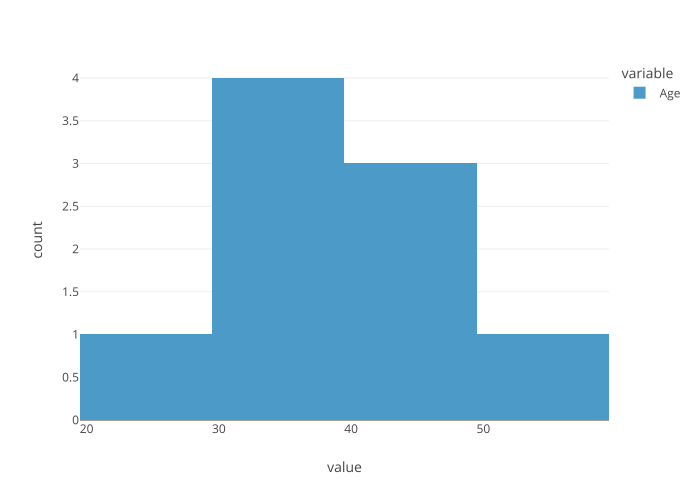

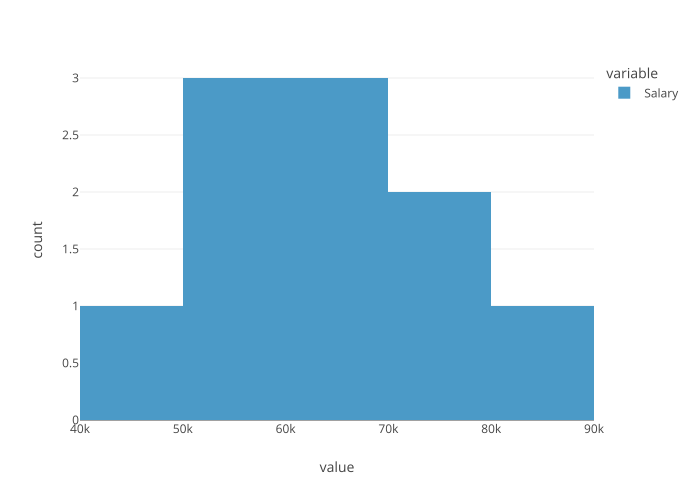

In [4]:
# Univariate analysis
# Distribution of each numeric variable
num_features = ['Age', 'Salary']
for i in range(len(num_features)):
    fig = px.histogram(dataset[num_features[i]])
    fig.show()

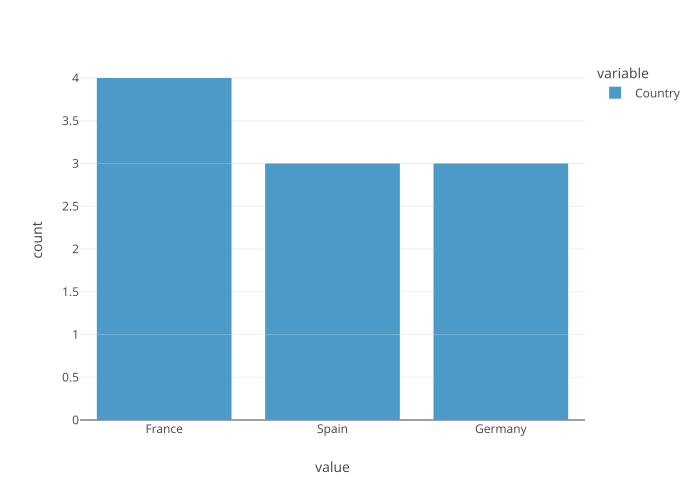

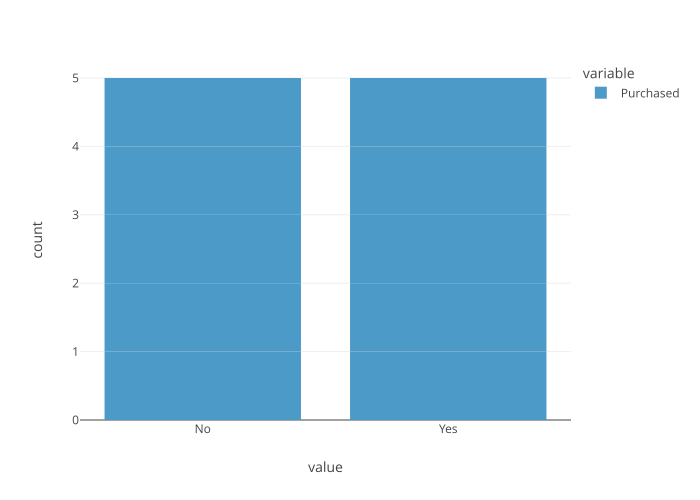

In [5]:
# Univariate analysis
# Barplot of each qualitative variable
cat_features = ['Country', 'Purchased']
for i in range(len(cat_features)):
    fig = px.bar(dataset[cat_features[i]])
    fig.show()

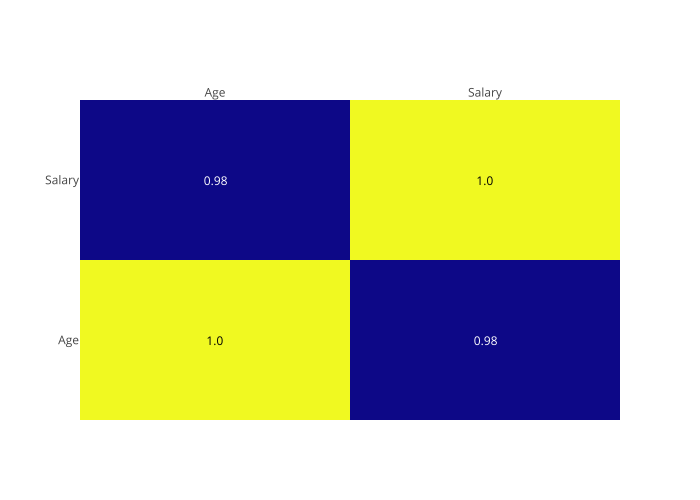

In [6]:
# Correlation matrix
corr_matrix = dataset.corr(numeric_only=True).round(2)

import plotly.figure_factory as ff

fig = ff.create_annotated_heatmap(corr_matrix.values,
                                  x = corr_matrix.columns.tolist(),
                                  y = corr_matrix.index.tolist())


fig.show()

Il existe une corrélation très forte entre la variable cible (Salary) et l’âge (Age) ! C’est une bonne nouvelle : cela signifie qu’un modèle linéaire reliant ces deux variables peut être un bon estimateur du salaire 🙂.  

Pour mieux comprendre les relations entre toutes les variables, analysons les scatterplots par paires (diagrammes de dispersion) afin d’examiner les interdépendances.

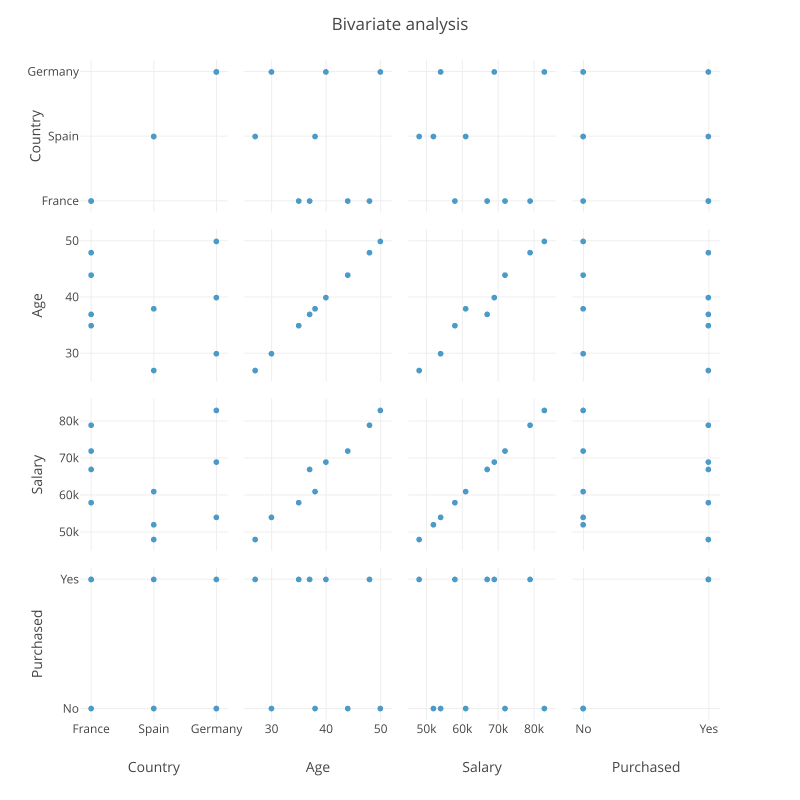

In [7]:
# Visualize pairwise dependencies
fig = px.scatter_matrix(dataset)
fig.update_layout(
        title = go.layout.Title(text = "Bivariate analysis", x = 0.5), showlegend = False, 
            autosize=False, height=800, width = 800)
fig.show()

Voici les principaux points à retenir de cette analyse bivariée:

* Corrélation Âge/Salaire : Il existe une relation linéaire positive directe, montrant que le salaire augmente de manière constante avec l'âge des individus.

* Profil des Acheteurs : Les décisions d'achat ("Yes") semblent plus fréquentes chez les profils ayant les salaires les plus élevés et les âges les plus avancés.

* Répartition Géographique : Les données sont collectées en France, en Espagne et en Allemagne, mais aucune distinction d'achat majeure ne saute aux yeux uniquement basée sur le pays sans croiser avec le revenu.

La tranche d'âge des 40-50 an avec un salaire supérieur à 70k a le plus de chances de conversion "Purchased".

## Baseline model : simple linear regression
Essayons d’abord un modèle simple : une régression linéaire utilisant une seule variable.
Nous choisissons Age, car nous avons vu qu’elle est fortement corrélée avec le salaire.

Objectifs d’un baseline model
* Établir une référence : il permet de savoir si les modèles plus complexes apportent vraiment une amélioration.
* Tester rapidement les données et le workflow : prétraitement, modélisation, évaluation.
* Identifier les variables importantes : même un modèle simple peut montrer quelles variables sont fortement corrélées à la cible.

In [8]:
# Separate target variable Y from features X
print("Separating labels from features...")
features_list = ["Age"]
target_variable = "Salary"

X = dataset.loc[:,features_list]
Y = dataset.loc[:,target_variable]

print("...Done.")
print()

print('Y : ')
print(Y.head())
print()
print('X :')
print(X.head())

Separating labels from features...
...Done.

Y : 
0    72000
1    48000
2    54000
3    61000
4    69000
Name: Salary, dtype: int64

X :
    Age
0  44.0
1  27.0
2  30.0
3  38.0
4  40.0


In [9]:
# Divide dataset Train set & Test set 
print("Dividing into train and test sets...")
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)
print("...Done.")
print()

Dividing into train and test sets...
...Done.



### Preprocessing

>Note : Simplified syntax
>
>Dans cet exemple, il n’est pas nécessaire d’utiliser la classe ColumnTransformer, car le prétraitement est très simple : une seule étape d’imputation suivie d’une standardisation, appliquées à l’ensemble du DataFrame (il n’y a en fait qu’une seule colonne !).
Dans ce cas, il suffit de créer un Pipeline qui décrit les différentes étapes, puis d’utiliser directement les méthodes fit_transform et transform en passant X_train/X_test en argument.

In [10]:
print("Preprocessing X_train...")
print(X_train.head())
print()
preprocessor = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
X_train = preprocessor.fit_transform(X_train)
print("...Done!")
print(X_train[0:5,:]) # X_train is now a numpy array
print() 

Preprocessing X_train...
    Age
4  40.0
9  37.0
1  27.0
6   NaN
7  48.0

...Done!
[[ 0.27978024]
 [-0.23673712]
 [-1.95846165]
 [-0.06456467]
 [ 1.65715986]]



In [11]:
# Test pipeline
print("Preprocessing X_test...")
print(X_test.head())
print()
X_test = preprocessor.transform(X_test)
print("...Done!")
print(X_test[0:5,:]) # X_test is now a numpy array
print() 

Preprocessing X_test...
    Age
2  30.0
8  50.0

...Done!
[[-1.44194429]
 [ 2.00150476]]



### Train model

In [12]:
# Train model
print("Train model...")
regressor = LinearRegression()
regressor.fit(X_train, Y_train)
print("...Done.")

Train model...
...Done.


### Performance assessment

In [13]:
# Predictions on training set
print("Predictions on training set...")
Y_train_pred = regressor.predict(X_train)
print("...Done.")
print(Y_train_pred)
print()

Predictions on training set...
...Done.
[65666.0490968  61205.65076424 46337.65632237 62692.45020843
 77560.4446503  62692.45020843 71613.24687355 58232.05187587]



In [14]:
# Predictions on test set
print("Predictions on test set...")
Y_test_pred = regressor.predict(X_test)
print("...Done.")
print(Y_test_pred)
print()

Predictions on test set...
...Done.
[50798.05465493 80534.04353868]



In [15]:
# Print R^2 scores
print("R2 score on training set : ", r2_score(Y_train, Y_train_pred))
print("R2 score on test set : ", r2_score(Y_test, Y_test_pred))

R2 score on training set :  0.7813729888409735
R2 score on test set :  0.9611572050845512


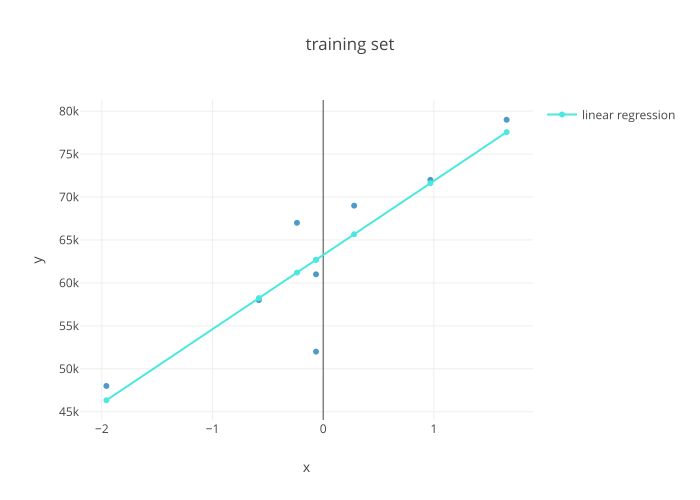

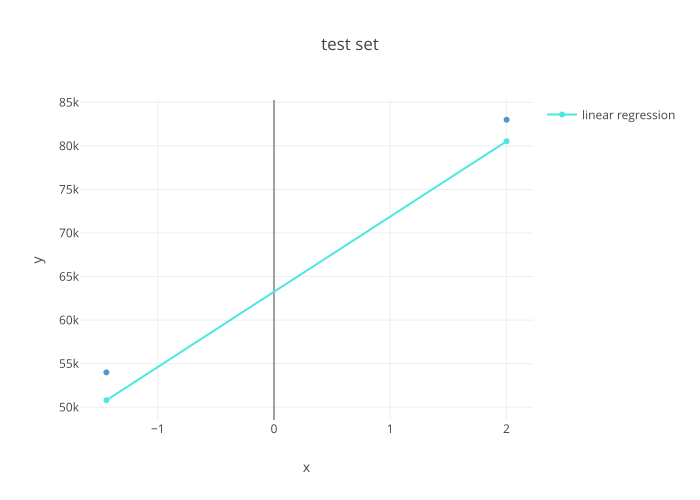

In [16]:
# Visualize the model
# Visualize predictions on training Set
fig = px.scatter(x = X_train.flatten().tolist(), y = Y_train, title = "training set")
fig.add_trace(go.Scatter(x = X_train.flatten().tolist(), y = Y_train_pred, name = "linear regression"))
fig.show()

# Visualize predictions on test Set
fig = px.scatter(x = X_test.flatten().tolist(), y = Y_test, title = "test set")
fig.add_trace(go.Scatter(x = X_test.flatten().tolist(), y = Y_test_pred, name = "linear regression"))
fig.show()

Dans l’exemple ci-dessus, **toutes les hypothèses nécessaires** pour entraîner un modèle de régression linéaire simple sont vérifiées :

* Il semble exister une **relation linéaire** entre la variable cible **Y** et la variable explicative **X**.
* Les **écarts entre les valeurs prédites et les valeurs réelles de Y** (les résidus) semblent **similaires pour toutes les valeurs de Y**, ce qui correspond à l’**homoscédasticité**.
* Il ne semble pas y avoir de **corrélation entre les résidus**, ceux-ci apparaissent **répartis de manière aléatoire** par rapport à toutes les valeurs de Y.

De plus, notre modèle semble être un **bon prédicteur** sur les échantillons d’entraînement utilisés.


## Multivariate linear regression
Entraînons maintenant un modèle linéaire multivarié en ajoutant les variables catégorielles : Country et Purchased.

In [17]:
# Separate target variable Y from features X
print("Separating labels from features...")
features_list = ["Country", "Age", "Purchased"]
target_variable = "Salary"

X = dataset.loc[:,features_list]
Y = dataset.loc[:,target_variable]

print("...Done.")
print()

print('Y : ')
print(Y.head())
print()
print('X :')
print(X.head())

Separating labels from features...
...Done.

Y : 
0    72000
1    48000
2    54000
3    61000
4    69000
Name: Salary, dtype: int64

X :
   Country   Age Purchased
0   France  44.0        No
1    Spain  27.0       Yes
2  Germany  30.0        No
3    Spain  38.0        No
4  Germany  40.0       Yes


In [18]:
# Automatically detect names of numeric/categorical columns
numeric_features = []
categorical_features = []
for column,type in X.dtypes.items():
    if ('float' in str(type)) or ('int' in str(type)) :
        numeric_features.append(column)
    else :
        categorical_features.append(column)

print('Found numeric features ', numeric_features)
print('Found categorical features ', categorical_features)

Found numeric features  ['Age']
Found categorical features  ['Country', 'Purchased']


In [19]:
# Divide dataset Train set & Test set 
print("Dividing into train and test sets...")
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)
print("...Done.")
print()

Dividing into train and test sets...
...Done.



### Preprocessing

In [20]:
# Create pipeline for numeric features
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')), # missing values will be replaced by columns' mean
    ('scaler', StandardScaler())
])

In [21]:
# Create pipeline for categorical features
categorical_transformer = Pipeline(
    steps=[
    ('encoder', OneHotEncoder(drop='first')) # first column will be dropped to avoid creating correlations between features
    ])

In [22]:
# Use ColumnTransformer to make a preprocessor object that describes all the treatments to be done
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

In [23]:
# Preprocessings on train set
print("Performing preprocessings on train set...")
print(X_train.head())
X_train = preprocessor.fit_transform(X_train)
print('...Done.')
print(X_train[0:5]) # MUST use this syntax because X_train is a numpy array and not a pandas DataFrame anymore
print()

# Preprocessings on test set
print("Performing preprocessings on test set...")
print(X_test.head()) 
X_test = preprocessor.transform(X_test) # Don't fit again !! The test set is used for validating decisions
# we made based on the training set, therefore we can only apply transformations that were parametered using the training set.
# Otherwise this creates what is called a leak from the test set which will introduce a bias in all your results.
print('...Done.')
print(X_test[0:5,:]) # MUST use this syntax because X_test is a numpy array and not a pandas DataFrame anymore
print()

Performing preprocessings on train set...
   Country   Age Purchased
4  Germany  40.0       Yes
9   France  37.0       Yes
1    Spain  27.0       Yes
6    Spain   NaN        No
7   France  48.0       Yes
...Done.
[[ 0.27063731  1.          0.          1.        ]
 [-0.24603392  0.          0.          1.        ]
 [-1.96827133  0.          1.          1.        ]
 [ 0.          0.          1.          0.        ]
 [ 1.64842723  0.          0.          1.        ]]

Performing preprocessings on test set...
   Country   Age Purchased
2  Germany  30.0        No
8  Germany  50.0        No
...Done.
[[-1.4516001   1.          0.          0.        ]
 [ 1.99287472  1.          0.          0.        ]]



### Train model

In [24]:
# Train model
print("Train model...")
regressor = LinearRegression()
regressor.fit(X_train, Y_train)
print("...Done.")

Train model...
...Done.


### Performance assessment

In [25]:
# Predictions on training set
print("Predictions on training set...")
Y_train_pred = regressor.predict(X_train)
print("...Done.")
print(Y_train_pred)
print()

Predictions on training set...
...Done.
[69000.         64690.01772977 46297.16942234 57628.38617903
 78907.85675999 57074.44439863 70297.16942234 62104.95608791]



In [26]:
# Predictions on test set
print("Predictions on test set...")
Y_test_pred = regressor.predict(X_test)
print("...Done.")
print(Y_test_pred)
print()

Predictions on test set...
...Done.
[52634.12773677 78484.74415536]



In [27]:
# Print R^2 scores
print("R2 score on training set : ", r2_score(Y_train, Y_train_pred))
print("R2 score on test set : ", r2_score(Y_test, Y_test_pred))

R2 score on training set :  0.9016592604305448
R2 score on test set :  0.9470793284613951


### Conclusion sur la qualité du modèle

On peut constater que le **R²-score** s’est **nettement amélioré** en passant d’une régression linéaire simple à une régression linéaire multiple. Cela s’explique par l’ajout de **variables explicatives réellement utiles** pour prédire la variable cible.

Cependant, **ajouter des variables supplémentaires n’améliore pas toujours les performances** ; dans certains cas, cela peut même les **détériorer**. C’est pourquoi, en général, il est nécessaire d’utiliser des **méthodes de sélection de variables** pour choisir les bonnes variables à inclure dans le modèle.

>Note : À propos de la visualisation
>
>Vous remarquerez que nous n’avons pas représenté graphiquement le modèle multivarié. C’est simplement **impossible** : pour représenter ce modèle, il faudrait **4 dimensions** (3 variables + la cible), alors que notre cerveau ne peut visualiser que **3 dimensions à la fois** 🥴.  
>
>C’est pour cette raison qu’il est **très important de calculer des métriques** comme le R²-score pour évaluer la qualité des prédictions. La plupart du temps, nous sommes « aveugles » sur ce qui se passe et devons **nous fier à ces scores** pour vérifier que le modèle prédit correctement. 


### Interpreting the model's coefficients

Comme nous avons **standardisé nos variables explicatives**, nous pouvons utiliser les **coefficients de la régression** pour estimer **l’importance de chaque variable** dans la prédiction.

Les paramètres du modèle sont **enregistrés dans l’attribut `.coef_`** : chaque coefficient indique **l’impact de la variable correspondante** sur la variable cible, toutes les variables étant sur la même échelle grâce à la standardisation.


In [28]:
regressor.coef_

array([ 7504.95148781,   432.38980745, -5467.54009813,  3440.56405393])

Chaque coefficient peut être **associé au nom de la variable correspondante** en examinant les différentes étapes du **pipeline** qui ont été utilisées pour produire les versions finales de **X_train/X_test**.

Cela permet de savoir **quelle variable a quel impact sur la prédiction**, même après les transformations appliquées dans le prétraitement.


In [29]:
column_names = []
for name, pipeline, features_list in preprocessor.transformers_: # loop over pipelines
    if name == 'num': # if pipeline is for numeric variables
        features = features_list # just get the names of columns to which it has been applied
    else: # if pipeline is for categorical variables
        features = pipeline.named_steps['encoder'].get_feature_names_out() # get output columns names from OneHotEncoder
    column_names.extend(features) # concatenate features names
        
print("Names of columns corresponding to each coefficient: ", column_names)

Names of columns corresponding to each coefficient:  ['Age', 'Country_Germany', 'Country_Spain', 'Purchased_Yes']


In [30]:
# Create a pandas DataFrame
coefs = pd.DataFrame(index = column_names, data = regressor.coef_.transpose(), columns=["coefficients"])
coefs

,coefficients
Age,7504.951488
Country_Germany,432.389807
Country_Spain,-5467.540098
Purchased_Yes,3440.564054


>Warning : Comparaison en valeurs absolues   
>
>L’importance des variables dépend des **valeurs absolues des coefficients**.  
N’oubliez pas de **prendre la valeur absolue** avant de tirer des conclusions sur l’impact relatif des variables !  



In [31]:
# Compute abs() and sort values
feature_importance = abs(coefs).sort_values(by = 'coefficients')
feature_importance

,coefficients
Country_Germany,432.389807
Purchased_Yes,3440.564054
Country_Spain,5467.540098
Age,7504.951488


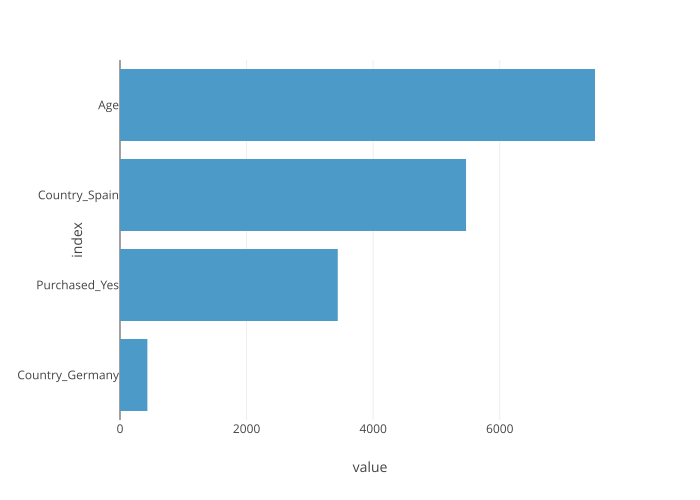

In [32]:
# Plot coefficients
fig = px.bar(feature_importance, orientation = 'h')
fig.update_layout(showlegend = False, 
                  margin = {'l': 120} # to avoid cropping of column names
                 )
fig.show()

## Resources 📚📚

- [Pandas API Reference](https://pandas.pydata.org/pandas-docs/version/1.5/reference/index.html)
- [Scikit-learn API Reference](https://scikit-learn.org/stable/api/index.html)